# UD1. Ejercicios propuestos

Este cuaderno acompaña a los ejercicios propuestos de la UD1 (apartado 11 de los apuntes): para cada uno, el enunciado, una celda con los **datos de partida** y mi solución comentada. La mayoría son ejercicios de pocas líneas de código y sin bucles.

Os pido un pequeño esfuerzo: **intentad resolverlos antes de consultar la solución** y, después, **comparad el razonamiento**, no solo los resultados. Si llegáis a la misma conclusión por otro camino, vuestra solución vale tanto como la mía.

> El código es el mismo que el de los apuntes y las celdas se ejecutan en orden. El ejercicio 5 reutiliza el DataFrame `cine` del ejercicio 4.


## Ejercicio 1. Obras publicadas en vida: el caso de Fanny Mendelssohn

A partir del DataFrame de compositoras del apartado 3, ampliado con las columnas que se consideren oportunas (años de vida, número de obras publicadas en vida frente a publicadas póstumamente), **calcular las matrices de Pearson y Spearman y comentar las diferencias**. **Investigar el caso de [Fanny Mendelssohn](https://es.wikipedia.org/wiki/Fanny_Mendelssohn)**, buena parte de cuya obra se publicó bajo el nombre de su hermano [Felix](https://es.wikipedia.org/wiki/Felix_Mendelssohn), y discutir cómo afectaría este hecho a un análisis basado solo en "obras publicadas en vida".

**Ayuda:** [`DataFrame.corr`](https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.corr.html) con `method="pearson"` y `method="spearman"`, [`scipy.stats.pearsonr`](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.pearsonr.html) y [`scipy.stats.spearmanr`](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.spearmanr.html).

**Datos de partida.** Al DataFrame del apartado 3 se ha añadido el **año de fallecimiento, los años de vida y el número de obras impresas en vida** con el nombre de la compositora. A partir de ellas se calculan las obras póstumas (que incluyen tanto las publicadas después de su muerte como las que siguen inéditas) y el porcentaje de obra publicada en vida.

Las cifras de obras son aproximadas. Los catálogos no coinciden entre fuentes y dependen del criterio de recuento (una colección de seis canciones puede contar como una obra o como seis). Los valores de la columna `en_vida` se han estimado así:

- **[Barbara Strozzi](https://es.wikipedia.org/wiki/Barbara_Strozzi)** publicó ocho colecciones entre 1644 y 1664, y tuvo en imprenta más música profana que ningún otro compositor de su época. Casi toda su obra conocida se imprimió en vida.
- **[Marianna Martines](https://es.wikipedia.org/wiki/Marianne_von_Martinez)** difundió su música en copias manuscritas. Apenas unas piezas llegaron a la imprenta en vida, y la primera edición de la mayor parte de su obra es reciente.
- **Fanny Mendelssohn** publicó con su nombre las colecciones op. 1 a op. 7, 32 piezas aparecidas entre 1846 y 1847, el año de su muerte. Las seis canciones que había publicado antes lo hicieron como obras de Felix.
- **[Clara Schumann](https://es.wikipedia.org/wiki/Clara_Schumann)** publicó en vida sus obras con número de opus (op. 1 a op. 23). Buena parte de las obras sin opus se editó después.
- **[Ethel Smyth](https://es.wikipedia.org/wiki/Ethel_Smyth)** vio publicada en vida la mayor parte de su producción principal (óperas, la Misa en re, canciones, música de cámara).
- **[Lili Boulanger](https://es.wikipedia.org/wiki/Lili_Boulanger)** murió a los 24 años. Ricordi publicó la cantata *Faust et Hélène* y algunas obras más, pero buena parte de su catálogo se editó tras su muerte.
- **[Hildegard von Bingen](https://es.wikipedia.org/wiki/Hildegarda_de_Bingen)** queda con un valor ausente (`NaN`). En el siglo XII no existía la imprenta y su obra circuló en códices manuscritos, así que la pregunta "¿se publicó en vida?" no tiene respuesta. Asignar un número sería inventar el dato.

Los años de vida se calculan como diferencia de años, de modo que pueden desviarse en uno de la edad real (Fanny Mendelssohn murió con 41 años, no con 42).

In [1]:
import numpy as np
import pandas as pd

compositoras = pd.DataFrame({
    "nombre": ["Hildegard von Bingen", "Barbara Strozzi",
               "Marianna Martines", "Fanny Mendelssohn",
               "Clara Schumann", "Ethel Smyth", "Lili Boulanger"],
    "nacimiento":    [1098, 1619, 1744, 1805, 1819, 1858, 1893],
    "fallecimiento": [1179, 1677, 1812, 1847, 1896, 1944, 1918],
    "obras":         [78, 125, 200, 460, 66, 90, 50],
    # Obras impresas en vida con su propio nombre (NaN: no había imprenta en el siglo XII)
    "en_vida":       [np.nan, 115, 3, 32, 25, 60, 8],
})

compositoras["anhos_vida"] = compositoras["fallecimiento"] - compositoras["nacimiento"]
compositoras["postumas"] = compositoras["obras"] - compositoras["en_vida"]
compositoras["pct_en_vida"] = 100 * compositoras["en_vida"] / compositoras["obras"]

print(compositoras.drop(columns="fallecimiento").round(1).to_string(index=False))

              nombre  nacimiento  obras  en_vida  anhos_vida  postumas  pct_en_vida
Hildegard von Bingen        1098     78      NaN          81       NaN          NaN
     Barbara Strozzi        1619    125    115.0          58      10.0         92.0
   Marianna Martines        1744    200      3.0          68     197.0          1.5
   Fanny Mendelssohn        1805    460     32.0          42     428.0          7.0
      Clara Schumann        1819     66     25.0          77      41.0         37.9
         Ethel Smyth        1858     90     60.0          86      30.0         66.7
      Lili Boulanger        1893     50      8.0          25      42.0         16.0


### Solución del ejercicio 1

**Matrices de correlación.** El método `corr()` trabaja por parejas con las observaciones completas: las columnas que dependen de `en_vida` se calculan con seis filas (sin Hildegard) y el resto con siete.

In [2]:
from scipy import stats

columnas = ["nacimiento", "anhos_vida", "obras", "en_vida", "postumas", "pct_en_vida"]

pearson = compositoras[columnas].corr(method="pearson")
spearman = compositoras[columnas].corr(method="spearman")

print("Pearson\n", pearson.round(2), sep="")
print("\nSpearman\n", spearman.round(2), sep="")
print("\nDiferencia (Spearman - Pearson)\n", (spearman - pearson).round(2), sep="")

Pearson
             nacimiento  anhos_vida  obras  en_vida  postumas  pct_en_vida
nacimiento         1.00       -0.39   0.17    -0.67      0.04        -0.47
anhos_vida        -0.39        1.00  -0.32     0.23     -0.30         0.41
obras              0.17       -0.32   1.00    -0.09      0.97        -0.44
en_vida           -0.67        0.23  -0.09     1.00     -0.34         0.92
postumas           0.04       -0.30   0.97    -0.34      1.00        -0.65
pct_en_vida       -0.47        0.41  -0.44     0.92     -0.65         1.00

Spearman
             nacimiento  anhos_vida  obras  en_vida  postumas  pct_en_vida
nacimiento         1.00       -0.21  -0.43    -0.26      0.09        -0.03
anhos_vida        -0.21        1.00  -0.07     0.20     -0.43         0.31
obras             -0.43       -0.07   1.00     0.14      0.43        -0.37
en_vida           -0.26        0.20   0.14     1.00     -0.66         0.83
postumas           0.09       -0.43   0.43    -0.66      1.00        -0.94
pct_en_

**Comentario (diferencias).** Las discrepancias grandes entre ambos coeficientes se explican, en todos los casos, por una o dos compositoras que ocupan una posición extrema:

- **`obras` y `postumas`**: Pearson da 0,97 y Spearman 0,43. Los catálogos de Fanny Mendelssohn (460 obras, 428 póstumas) y de Marianna Martines (200 y 197) quedan muy lejos del resto y arrastran a Pearson. Además, la relación está fabricada en parte por construcción: `postumas` es `obras` menos `en_vida`, de modo que cuando se publica poco en vida ambas columnas casi coinciden. Una correlación alta entre una variable y otra derivada de ella no descubre nada.
- **`nacimiento` y `obras`**: los coeficientes tienen **signo distinto** (0,17 frente a -0,43). Hildegard, nacida cinco siglos antes que las demás, y el gran catálogo de Fanny pesan mucho en Pearson; Spearman solo ve el orden, en el que las tres compositoras más tardías tienen catálogos pequeños. Cuando dos coeficientes no se ponen de acuerdo ni en el signo, lo razonable es concluir que no hay una relación clara que describir.
- **`nacimiento` y `en_vida`** (-0,67 frente a -0,26) y **`nacimiento` y `pct_en_vida`** (-0,47 frente a -0,03): el Pearson negativo se debe casi por completo a Barbara Strozzi, la más antigua de las seis con datos y la que más publicó. Con los rangos, la relación prácticamente desaparece.
- **`en_vida` y `pct_en_vida`**: los dos coeficientes son altos (0,92 y 0,83). Es la única relación estable, y es esperable, porque la segunda variable es la primera dividida entre el total de obras.

Con seis o siete filas, ninguna de estas cifras permite generalizar. La comprobación siguiente lo muestra con la pareja de correlación más alta:

In [3]:
completas = compositoras.dropna()          # sin Hildegard: 6 filas
sin_fanny = completas[completas["nombre"] != "Fanny Mendelssohn"]

for datos, etiqueta in [(completas, "con Fanny"), (sin_fanny, "sin Fanny")]:
    r, p_r = stats.pearsonr(datos["obras"], datos["postumas"])
    rho, p_rho = stats.spearmanr(datos["obras"], datos["postumas"])
    print(f"obras / postumas, {etiqueta}: r = {r:.2f} (p = {p_r:.3f})   "
          f"rho = {rho:.2f} (p = {p_rho:.3f})")

obras / postumas, con Fanny: r = 0.97 (p = 0.002)   rho = 0.43 (p = 0.397)
obras / postumas, sin Fanny: r = 0.79 (p = 0.113)   rho = 0.00 (p = 1.000)


El único p-valor por debajo de 0,05 de todo el análisis corresponde a una correlación construida por definición y sostenida por una sola compositora: al retirarla, deja de ser significativa. Es el apartado 4.4 en miniatura.

**El caso de Fanny Mendelssohn.** Nacida en 1805 en una familia acomodada de Hamburgo, recibió la misma formación musical que su hermano Felix y fue una pianista y compositora excepcional. En 1820 su padre le escribió que la música quizá sería la profesión de Felix, mientras que para ella solo podía y debía ser un adorno. Felix, que admiraba su talento, se opuso también a que publicara. Entre 1827 y 1830 aparecieron seis canciones suyas (tres en el op. 8 y tres en el op. 9 de Felix) como obras de su hermano. En 1842 la reina [Victoria](https://es.wikipedia.org/wiki/Victoria_del_Reino_Unido) recibió a Felix en el palacio de Buckingham y quiso cantarle su canción favorita de él, *Italien*; Felix tuvo que confesar que era de Fanny. Ella no publicó con su nombre hasta 1846, sin consultar a Felix, y murió en mayo de 1847. De sus más de 460 obras, casi todas quedaron manuscritas y la mayoría no se editó hasta finales del siglo XX.

¿Cómo afecta esto a un análisis basado solo en "obras publicadas en vida"? En este DataFrame, el efecto numérico es pequeño:

In [4]:
# Recuento alternativo: se atribuyen a Fanny las seis canciones publicadas como de Felix
autoria_real = compositoras.copy()
autoria_real.loc[autoria_real["nombre"] == "Fanny Mendelssohn", "en_vida"] += 6
autoria_real["postumas"] = autoria_real["obras"] - autoria_real["en_vida"]
autoria_real["pct_en_vida"] = 100 * autoria_real["en_vida"] / autoria_real["obras"]

for metodo in ["pearson", "spearman"]:
    antes = compositoras[columnas].corr(method=metodo)
    despues = autoria_real[columnas].corr(method=metodo)
    cambio = (despues - antes).abs().to_numpy().max()
    print(f"{metodo}: mayor cambio en la matriz = {cambio:.3f}")

pearson: mayor cambio en la matriz = 0.055
spearman: mayor cambio en la matriz = 0.000


Pearson cambia como mucho 0,055, y Spearman nada en absoluto, porque pasar de 32 a 38 obras no altera el orden de Fanny respecto de las demás. Pero el problema de fondo no es numérico, sino de **validez de la variable**:

1. **La variable no mide lo que parece medir.** "Obras publicadas en vida" no mide productividad ni calidad, sino el acceso a la imprenta con el propio nombre. Para una mujer del siglo XIX ese acceso dependía del permiso familiar y de las normas sociales. Un 7 % de obra publicada en vida dice mucho sobre las condiciones de Fanny y casi nada sobre su música.
2. **El error de medida no es aleatorio.** Las canciones atribuidas a Felix restan obras a Fanny y se las suman a él: el error siempre juega en la misma dirección. No es un caso aislado. [Augusta Holmès](https://es.wikipedia.org/wiki/Augusta_Holm%C3%A8s) publicó sus primeras obras con el seudónimo masculino de Hermann Zenta, y la publicación anónima o bajo nombre de un familiar fue frecuente. Con un conjunto grande de compositores y compositoras, este sesgo sistemático produciría correlaciones espurias con el sexo que se atribuirían a diferencias de producción.
3. **También el total de obras está condicionado.** Los 460 títulos del catálogo de Fanny se conocen gracias al trabajo de recuperación de sus manuscritos durante el siglo XX. El número de obras que figura en un catálogo mide, en parte, cuánto se ha investigado sobre cada autora.
4. **Consecuencia para el aprendizaje automático.** Un modelo que usara "obras publicadas en vida" como indicador de relevancia aprendería y reproduciría la exclusión histórica, igual que el sistema de selección de personal del apartado 8. Antes de calcular correlaciones hay que preguntarse cómo se generó cada variable y a quién perjudican sus errores.

## Ejercicio 2. Una relación periódica: el seno con ruido

Generar 200 puntos de la función $y = \sin(x)$ con $x \in [0, 4\pi]$ más ruido gaussiano. **Calcular Pearson, Spearman e información mutua y explicar por qué cada coeficiente devuelve el valor que devuelve.**

**Ayuda:** [`np.linspace`](https://numpy.org/doc/stable/reference/generated/numpy.linspace.html), [`scipy.stats.pearsonr`](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.pearsonr.html), [`scipy.stats.spearmanr`](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.spearmanr.html) y [`mutual_info_regression`](https://scikit-learn.org/stable/modules/generated/sklearn.feature_selection.mutual_info_regression.html). Repaso en el apartado 6.

**Datos de partida.** Se toman 200 valores de $x$ equiespaciados y un ruido gaussiano de desviación típica 0,3.

In [5]:
import numpy as np

rng = np.random.default_rng(2026)
n = 200
x = np.linspace(0, 4 * np.pi, n)            # dos periodos completos
y = np.sin(x) + rng.normal(0, 0.3, n)       # seno más ruido gaussiano

### Solución del ejercicio 2

Como referencia para la información mutua se calcula también su valor con $y$ barajada, es decir, sin relación con $x$.

Pearson:           r   = -0.347   (p = 4.6e-07)
Spearman:          rho = -0.345   (p = 5.4e-07)
Información mutua: IM  = 0.701 nats
IM con y barajada:       0.000 nats
IM equivalente a |r| = 0.35: 0.064 nats
Sin ruido, x en [0, 0 + 4pi]: r = -0.387
Sin ruido, x en [pi/2, pi/2 + 4pi]: r = -0.000
Sin ruido, x en [pi, pi + 4pi]: r = +0.387


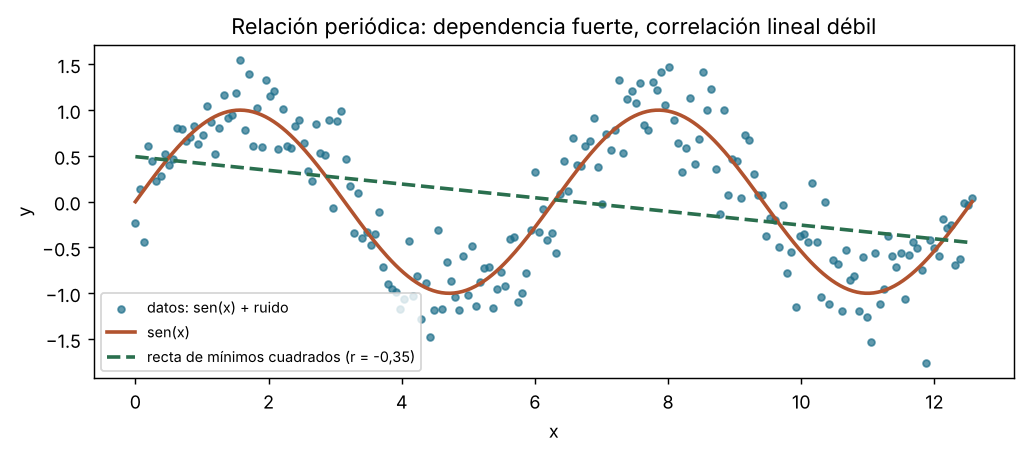

In [6]:
import matplotlib.pyplot as plt
from scipy import stats
from sklearn.feature_selection import mutual_info_regression

r, p_r = stats.pearsonr(x, y)
rho, p_rho = stats.spearmanr(x, y)
im = mutual_info_regression(x.reshape(-1, 1), y, random_state=2026)[0]

print(f"Pearson:           r   = {r:.3f}   (p = {p_r:.1e})")
print(f"Spearman:          rho = {rho:.3f}   (p = {p_rho:.1e})")
print(f"Información mutua: IM  = {im:.3f} nats")

# Referencia: la misma y barajada, de modo que deja de depender de x
im_barajada = mutual_info_regression(x.reshape(-1, 1), rng.permutation(y),
                                     random_state=2026)[0]
print(f"IM con y barajada:       {im_barajada:.3f} nats")

# Información mutua que tendría una relación lineal gaussiana con ese mismo r
print(f"IM equivalente a |r| = {abs(r):.2f}: {-0.5 * np.log(1 - r**2):.3f} nats")

# El valor de Pearson depende de la ventana de x elegida
for inicio, nombre in [(0, "0"), (np.pi / 2, "pi/2"), (np.pi, "pi")]:
    xv = np.linspace(inicio, inicio + 4 * np.pi, n)
    print(f"Sin ruido, x en [{nombre}, {nombre} + 4pi]: r = {np.corrcoef(xv, np.sin(xv))[0, 1]:+.3f}")

fig, ax = plt.subplots(figsize=(8, 3.6))
ax.scatter(x, y, s=14, color="#1f6f8b", alpha=0.7, label="datos: sen(x) + ruido")
xx = np.linspace(0, 4 * np.pi, 400)
ax.plot(xx, np.sin(xx), color="#b1532f", lw=2, label="sen(x)")
recta = np.polyfit(x, y, 1)
ax.plot(xx, np.polyval(recta, xx), color="#2a6f4e", lw=2, ls="--",
        label=f"recta de mínimos cuadrados (r = {r:.2f})".replace(".", ","))
ax.set_xlabel("x")
ax.set_ylabel("y")
ax.set_title("Relación periódica: dependencia fuerte, correlación lineal débil")
ax.legend(loc="lower left", fontsize=8)
fig.tight_layout()
plt.show()

**Pearson: -0,35.** Podría esperarse un valor nulo, porque el seno no crece ni decrece "en conjunto". Sin embargo, en cada periodo la mitad positiva va antes que la negativa, y la recta de mínimos cuadrados sale ligeramente descendente. Sin ruido, el valor puede calcularse de forma exacta. Con $x$ uniforme en $[0, 4\pi]$, la media de $x$ es $2\pi$ y

$$\text{cov}(x, \sin x) = \frac{1}{4\pi}\int_0^{4\pi}(x - 2\pi)\sin x \, dx = -1, \qquad s_x = \frac{4\pi}{\sqrt{12}}, \qquad s_y = \frac{1}{\sqrt{2}}$$

de donde $r = -\sqrt{6}/(2\pi) \approx -0{,}39$. El ruido añade varianza a $y$ sin añadir covarianza, y rebaja el valor a unos -0,36, próximo al -0,35 obtenido. El resultado depende por completo de la ventana: al desplazarla $\pi/2$ el coeficiente vale 0, y al desplazarla $\pi$ cambia de signo. El -0,35 no describe la relación entre $x$ e $y$, sino un detalle de dónde empieza y termina el intervalo.

**Spearman: -0,35, prácticamente igual.** Spearman solo mejora a Pearson cuando la relación es monótona. Aquí $y$ sube y baja dos veces. Además, los rangos de $x$ son equiespaciados, igual que los propios valores, y sustituir $y$ por sus rangos es una transformación monótona que apenas altera la tendencia global. Los dos coeficientes miden, en la práctica, lo mismo.

**Información mutua: 0,70 nats.** Es el único de los tres valores que refleja la realidad: $y$ queda casi determinada por $x$, salvo el ruido. El estimador de scikit-learn se basa en vecinos próximos, y comprueba si puntos con $x$ parecida tienen también $y$ parecida, sin suponer ninguna forma funcional. Con $y$ barajada el valor cae a 0. Para dar escala al número, una relación lineal gaussiana tiene una información mutua de $-\tfrac{1}{2}\ln(1 - r^2)$. Con $r = -0{,}35$ serían 0,06 nats; los 0,70 obtenidos equivalen a una correlación lineal de 0,87.

**Consecuencia para el modelado.** Con Pearson y Spearman se descartaría $x$ como variable poco relevante, cuando es la que explica casi todo. Un modelo lineal en $x$ sería inútil. Harían falta variables transformadas ($\sin x$, $\cos x$) o un modelo no paramétrico, como los k vecinos o los árboles de decisión.

## Ejercicio 3. Valores atípicos: Pearson frente a Spearman

**Reproducir el experimento del valor atípico del apartado 4.4** y comprobar numéricamente que Spearman apenas se altera mientras Pearson se dispara. **Repetir con 2 y con 5 valores atípicos y representar la evolución de ambos coeficientes.**

**Ayuda:** [`np.append`](https://numpy.org/doc/stable/reference/generated/numpy.append.html), [`scipy.stats.pearsonr`](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.pearsonr.html) y [`scipy.stats.spearmanr`](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.spearmanr.html).

**Datos de partida.** Se parte de los mismos 50 puntos independientes del apartado 4.4 (semilla 0) y se preparan hasta 10 valores atípicos en torno a (30, 30), con una pequeña dispersión para que no empaten entre sí.

In [7]:
import numpy as np

# Mismos datos que en el apartado 4.4
rng = np.random.default_rng(0)
x = rng.normal(5, 1, 50)
y = rng.normal(5, 1, 50)

# Hasta 10 atípicos en torno a (30, 30), con algo de dispersión para evitar empates
rng_atip = np.random.default_rng(2026)
max_atipicos = 10
atip_x = 30 + rng_atip.normal(0, 1, max_atipicos)
atip_y = 30 + rng_atip.normal(0, 1, max_atipicos)

### Solución del ejercicio 3

          pearson  spearman
atipicos                   
0          -0.108    -0.055
1           0.922     0.006
2           0.959     0.062
5           0.981     0.207
10          0.989     0.386
5 atípicos en torno a 30: Pearson = 0.981, Spearman = 0.207
5 atípicos en torno a 300: Pearson = 0.999, Spearman = 0.207


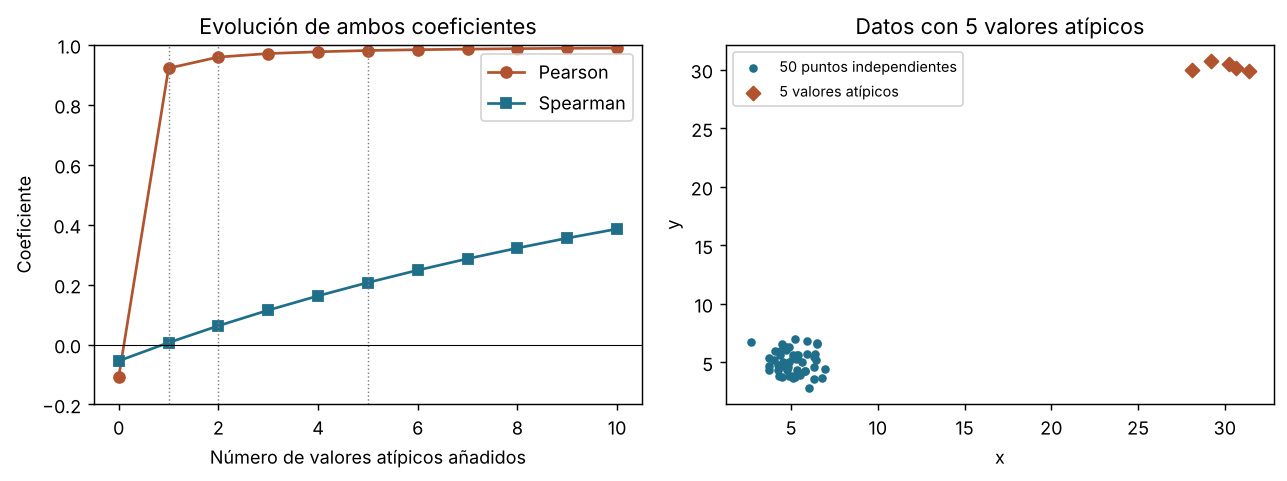

In [8]:
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

filas = []
for k in range(max_atipicos + 1):
    xk = np.append(x, atip_x[:k])
    yk = np.append(y, atip_y[:k])
    filas.append({"atipicos": k,
                  "pearson": stats.pearsonr(xk, yk)[0],
                  "spearman": stats.spearmanr(xk, yk)[0]})

evolucion = pd.DataFrame(filas).set_index("atipicos")
print(evolucion.loc[[0, 1, 2, 5, 10]].round(3))

# ¿Depende Spearman de lo extremos que sean los atípicos?
for centro in [30, 300]:
    xk = np.append(x, atip_x[:5] * centro / 30)
    yk = np.append(y, atip_y[:5] * centro / 30)
    print(f"5 atípicos en torno a {centro}: Pearson = {stats.pearsonr(xk, yk)[0]:.3f}, "
          f"Spearman = {stats.spearmanr(xk, yk)[0]:.3f}")

fig, axes = plt.subplots(1, 2, figsize=(10, 3.8))
ax = axes[0]
ax.plot(evolucion.index, evolucion["pearson"], "o-", color="#b1532f", label="Pearson")
ax.plot(evolucion.index, evolucion["spearman"], "s-", color="#1f6f8b", label="Spearman")
for k in [1, 2, 5]:
    ax.axvline(k, color="grey", lw=0.8, ls=":")
ax.axhline(0, color="black", lw=0.6)
ax.set_xlabel("Número de valores atípicos añadidos")
ax.set_ylabel("Coeficiente")
ax.set_ylim(-0.2, 1.0)
ax.set_title("Evolución de ambos coeficientes")
ax.legend()

ax = axes[1]
ax.scatter(x, y, s=14, color="#1f6f8b", label="50 puntos independientes")
ax.scatter(atip_x[:5], atip_y[:5], s=30, color="#b1532f", marker="D", label="5 valores atípicos")
ax.set_xlabel("x")
ax.set_ylabel("y")
ax.set_title("Datos con 5 valores atípicos")
ax.legend(fontsize=8, loc="upper left")
fig.tight_layout()
plt.show()

**Resultados.**

| Atípicos | Pearson | Spearman |
|---:|---:|---:|
| 0 | -0,108 | -0,055 |
| 1 | 0,922 | 0,006 |
| 2 | 0,959 | 0,062 |
| 5 | 0,981 | 0,207 |

**Un solo atípico** basta para que Pearson pase de -0,11 a 0,92, mientras Spearman se mueve 0,06. Queda comprobado lo que afirma el apartado 4.4: el atípico está a 25 desviaciones típicas del resto y domina por sí solo la covarianza, mientras que para Spearman es simplemente el que ocupa el último rango en las dos variables.

**Con 2 y con 5 atípicos** Pearson se satura cerca de 1: a partir del primero, la nube de 50 puntos es poco más que una mancha frente a un segundo grupo lejano. Spearman, en cambio, crece de forma gradual (0,06 y 0,21), y con 10 atípicos llega a 0,39.

No se debe pasar por alto este crecimiento. Spearman es robusto frente a la **magnitud** de los atípicos, pero no frente a su **número**. Cada atípico ocupa los rangos más altos en $x$ y en $y$ a la vez y aporta concordancia, y su efecto crece con la proporción de datos que representan. La última comprobación del código lo confirma: llevar los cinco atípicos de 30 a 300 deja Spearman exactamente igual (0,207), mientras Pearson sube todavía más, hasta 0,999.

Cuando los "atípicos" son el 10 % o el 20 % de los datos ya no son atípicos, sino un subgrupo. Ningún coeficiente resuelve esa situación por sí mismo: hay que dibujar los datos (Anscombe otra vez) y decidir si se trata de errores de medida que deben depurarse o de una población distinta que se debe analizar por separado.

## Ejercicio 4. Correlaciones en una muestra de cine clásico

A partir de un conjunto de **películas de cine clásico de al menos 30 títulos**, con año, duración, país y valoración, **calcular la matriz de correlaciones, representarla como mapa de calor y redactar un breve informe con las conclusiones**, indicando expresamente **qué afirmaciones causales NO pueden hacerse** a partir de las correlaciones encontradas.

Se facilita un conjunto de 36 películas. Quien lo prefiera puede construir el suyo a partir de cualquier fuente pública de datos de cine, como los [conjuntos de datos no comerciales de IMDb](https://developer.imdb.com/non-commercial-datasets/) o [Wikidata](https://www.wikidata.org/).

**Ayuda:** [`DataFrame.corr`](https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.corr.html), [`seaborn.heatmap`](https://seaborn.pydata.org/generated/seaborn.heatmap.html), [`scipy.stats.pearsonr`](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.pearsonr.html) y [`scipy.stats.spearmanr`](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.spearmanr.html). Repaso en los apartados 4 y 8.

**Datos de partida.** El conjunto recoge 36 películas estrenadas entre 1920 y 1966 en once países. Incluye las doce del apartado 4.2, con los mismos valores, y añade otras veinticuatro, con obras de [Akira Kurosawa](https://es.wikipedia.org/wiki/Akira_Kurosawa), [Satyajit Ray](https://es.wikipedia.org/wiki/Satyajit_Ray), [Luis García Berlanga](https://es.wikipedia.org/wiki/Luis_Garc%C3%ADa_Berlanga) o [Federico Fellini](https://es.wikipedia.org/wiki/Federico_Fellini). Solo tres están dirigidas por mujeres: *The Hitch-Hiker*, de [Ida Lupino](https://es.wikipedia.org/wiki/Ida_Lupino), única película de cine negro del periodo clásico dirigida por una mujer; *Cleo de 5 a 7*, de [Agnès Varda](https://es.wikipedia.org/wiki/Agn%C3%A8s_Varda); y *Las margaritas*, de [Věra Chytilová](https://es.wikipedia.org/wiki/V%C4%9Bra_Chytilov%C3%A1). La proporción no es un descuido de la selección, sino un reflejo de quién pudo dirigir en esos años y de quién ha entrado en el canon.

Sobre las columnas:

- `duracion` es la de la versión de referencia en minutos. Algunas películas mudas circulan en montajes de distinta duración.
- `pais` es el país principal de producción.
- `valoracion` es la valoración media aproximada de los usuarios de IMDb (escala de 1 a 10), redondeada a una décima. Es una media de votos que cambia con el tiempo, de modo que se recomienda actualizarla si se necesita la cifra exacta.

In [9]:
import pandas as pd

cine = pd.DataFrame(
    [
        ("El gabinete del doctor Caligari", "Robert Wiene",         1920, 76,  "Alemania",       8.0),
        ("Nosferatu",                       "F. W. Murnau",         1922, 94,  "Alemania",       7.9),
        ("El acorazado Potemkin",           "Serguéi Eisenstein",   1925, 75,  "URSS",           7.4),
        ("Metrópolis",                      "Fritz Lang",           1927, 153, "Alemania",       8.3),
        ("Amanecer",                        "F. W. Murnau",         1927, 94,  "EE. UU.",        8.1),
        ("M, el vampiro de Düsseldorf",     "Fritz Lang",           1931, 117, "Alemania",       8.3),
        ("Luces de la ciudad",              "Charles Chaplin",      1931, 87,  "EE. UU.",        8.5),
        ("Tiempos modernos",                "Charles Chaplin",      1936, 87,  "EE. UU.",        8.5),
        ("La gran ilusión",                 "Jean Renoir",          1937, 113, "Francia",        8.1),
        ("La regla del juego",              "Jean Renoir",          1939, 110, "Francia",        7.9),
        ("Lo que el viento se llevó",       "Victor Fleming",       1939, 238, "EE. UU.",        8.2),
        ("Ciudadano Kane",                  "Orson Welles",         1941, 119, "EE. UU.",        8.3),
        ("Casablanca",                      "Michael Curtiz",       1942, 102, "EE. UU.",        8.5),
        ("Roma, ciudad abierta",            "Roberto Rossellini",   1945, 103, "Italia",         8.0),
        ("Ladrón de bicicletas",            "Vittorio De Sica",     1948, 89,  "Italia",         8.3),
        ("El tercer hombre",                "Carol Reed",           1949, 104, "Reino Unido",    8.1),
        ("Rashomon",                        "Akira Kurosawa",       1950, 88,  "Japón",          8.2),
        ("El crepúsculo de los dioses",     "Billy Wilder",         1950, 110, "EE. UU.",        8.4),
        ("Vivir",                           "Akira Kurosawa",       1952, 143, "Japón",          8.3),
        ("Cantando bajo la lluvia",         "Stanley Donen y Gene Kelly", 1952, 103, "EE. UU.",  8.3),
        ("Cuentos de Tokio",                "Yasujiro Ozu",         1953, 136, "Japón",          8.2),
        ("Bienvenido, Mister Marshall",     "Luis García Berlanga", 1953, 78,  "España",         7.6),
        ("The Hitch-Hiker",                 "Ida Lupino",           1953, 71,  "EE. UU.",        7.0),
        ("Los siete samuráis",              "Akira Kurosawa",       1954, 207, "Japón",          8.6),
        ("La strada",                       "Federico Fellini",     1954, 108, "Italia",         8.0),
        ("Pather Panchali",                 "Satyajit Ray",         1955, 125, "India",          8.2),
        ("El séptimo sello",                "Ingmar Bergman",       1957, 96,  "Suecia",         8.2),
        ("Vértigo",                         "Alfred Hitchcock",     1958, 128, "EE. UU.",        8.3),
        ("Los cuatrocientos golpes",        "François Truffaut",    1959, 99,  "Francia",        8.1),
        ("Psicosis",                        "Alfred Hitchcock",     1960, 109, "EE. UU.",        8.5),
        ("La dolce vita",                   "Federico Fellini",     1960, 174, "Italia",         8.0),
        ("Cleo de 5 a 7",                   "Agnès Varda",          1962, 90,  "Francia",        7.8),
        ("8 y medio",                       "Federico Fellini",     1963, 138, "Italia",         8.1),
        ("El verdugo",                      "Luis García Berlanga", 1963, 90,  "España",         8.0),
        ("Las margaritas",                  "Věra Chytilová",       1966, 74,  "Checoslovaquia", 7.2),
        ("Persona",                         "Ingmar Bergman",       1966, 85,  "Suecia",         8.1),
    ],
    columns=["titulo", "direccion", "anho", "duracion", "pais", "valoracion"],
)

print(cine.shape)                                   # (36, 6)
print(cine["pais"].value_counts().to_dict())
print(cine[["anho", "duracion", "valoracion"]].describe().round(2))

(36, 6)
{'EE. UU.': 11, 'Italia': 5, 'Alemania': 4, 'Francia': 4, 'Japón': 4, 'España': 2, 'Suecia': 2, 'URSS': 1, 'Reino Unido': 1, 'India': 1, 'Checoslovaquia': 1}
          anho  duracion  valoracion
count    36.00     36.00       36.00
mean   1947.19    111.47        8.10
std      13.17     36.08        0.35
min    1920.00     71.00        7.00
25%    1938.50     88.75        8.00
50%    1951.00    103.00        8.15
75%    1957.25    120.50        8.30
max    1966.00    238.00        8.60


### Solución del ejercicio 4

**Cálculo.** Se obtienen las matrices de Pearson y Spearman, los p-valores de cada pareja y, junto al mapa de calor, el diagrama de dispersión de la única pareja con una correlación apreciable.

            anho  duracion  valoracion
anho        1.00      0.06       -0.09
duracion    0.06      1.00        0.41
valoracion -0.09      0.41        1.00

            anho  duracion  valoracion
anho        1.00      0.06       -0.13
duracion    0.06      1.00        0.43
valoracion -0.13      0.43        1.00
anho / duracion: r = +0.06 (p = 0.74)   rho = +0.06 (p = 0.72)
anho / valoracion: r = -0.09 (p = 0.59)   rho = -0.13 (p = 0.44)
duracion / valoracion: r = +0.41 (p = 0.01)   rho = +0.43 (p = 0.01)


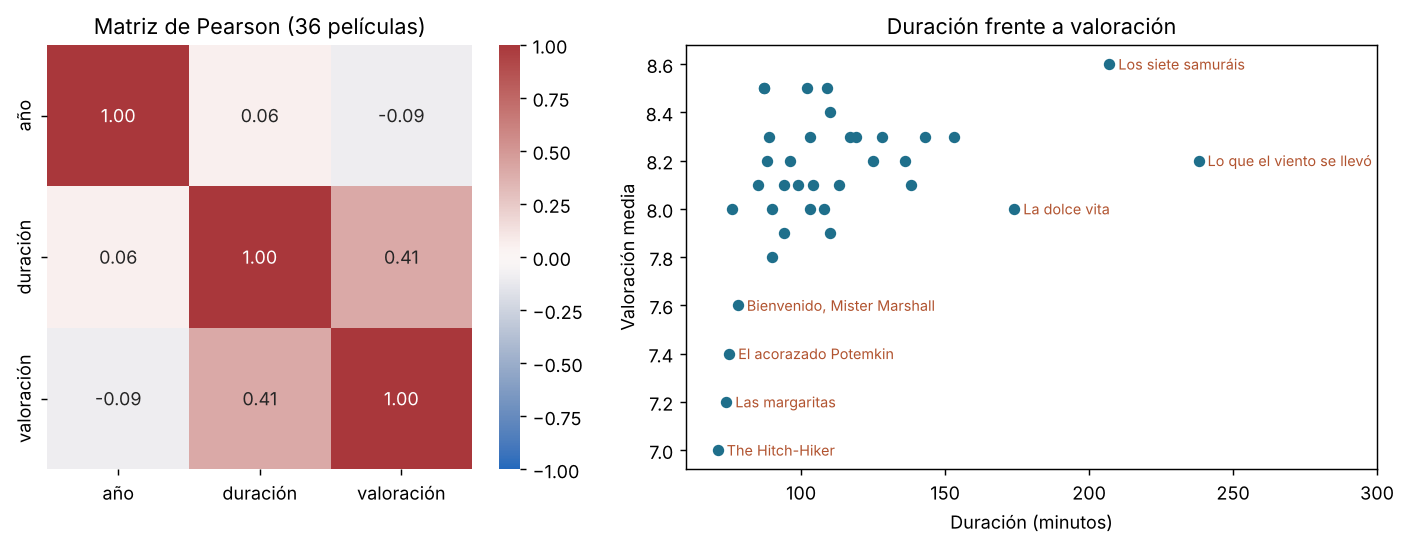

In [10]:
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

numericas = ["anho", "duracion", "valoracion"]
etiquetas = ["año", "duración", "valoración"]

pearson = cine[numericas].corr(method="pearson")
spearman = cine[numericas].corr(method="spearman")
print(pearson.round(2), spearman.round(2), sep="\n\n")

# Coeficientes con su p-valor, pareja a pareja
for a, b in [("anho", "duracion"), ("anho", "valoracion"), ("duracion", "valoracion")]:
    r, p_r = stats.pearsonr(cine[a], cine[b])
    rho, p_rho = stats.spearmanr(cine[a], cine[b])
    print(f"{a} / {b}: r = {r:+.2f} (p = {p_r:.2f})   rho = {rho:+.2f} (p = {p_rho:.2f})")

fig, axes = plt.subplots(1, 2, figsize=(11, 4.3), gridspec_kw={"width_ratios": [1, 1.3]})
sns.heatmap(pearson, annot=True, fmt=".2f", cmap="vlag", vmin=-1, vmax=1, square=True,
            xticklabels=etiquetas, yticklabels=etiquetas, ax=axes[0])
axes[0].set_title("Matriz de Pearson (36 películas)")

ax = axes[1]
ax.scatter(cine["duracion"], cine["valoracion"], color="#1f6f8b", s=28)
for _, fila in cine[(cine["valoracion"] < 7.7) | (cine["duracion"] > 170)].iterrows():
    ax.annotate(fila["titulo"], (fila["duracion"], fila["valoracion"]),
                xytext=(5, -3), textcoords="offset points", fontsize=8, color="#b1532f")
ax.set_xlim(60, 300)
ax.set_xlabel("Duración (minutos)")
ax.set_ylabel("Valoración media")
ax.set_title("Duración frente a valoración")
fig.tight_layout()
plt.show()

El diagrama de dispersión sugiere que la correlación descansa en unas pocas películas. Merece la pena comprobarlo:

In [11]:
# ¿Se sostiene la correlación sin los casos más extremos?
casos = {
    "todas": cine,
    "sin las dos de más de 200 min": cine[cine["duracion"] < 200],
    "sin las cuatro peor valoradas": cine[cine["valoracion"] >= 7.7],
}
for nombre, datos in casos.items():
    r, p_r = stats.pearsonr(datos["duracion"], datos["valoracion"])
    rho, p_rho = stats.spearmanr(datos["duracion"], datos["valoracion"])
    print(f"{nombre:<31} n = {len(datos)}  r = {r:.2f} (p = {p_r:.2f})  "
          f"rho = {rho:.2f} (p = {p_rho:.2f})")

todas                           n = 36  r = 0.41 (p = 0.01)  rho = 0.43 (p = 0.01)
sin las dos de más de 200 min   n = 34  r = 0.42 (p = 0.01)  rho = 0.38 (p = 0.03)
sin las cuatro peor valoradas   n = 32  r = 0.21 (p = 0.25)  rho = 0.18 (p = 0.32)


**Informe**

*Datos.* Muestra de 36 películas de once países, estrenadas entre 1920 y 1966, con tres variables numéricas: año, duración y valoración media de IMDb. Las valoraciones se concentran entre 7,0 y 8,6, con una desviación típica de solo 0,35.

*Resultados.*

- El año de estreno no se relaciona con la duración ($r = 0{,}06$) ni con la valoración ($r = -0{,}09$; $\rho = -0{,}13$). Ninguna de las dos correlaciones es significativa.
- La duración y la valoración muestran una correlación positiva moderada ($r = 0{,}41$; $\rho = 0{,}43$; $p = 0{,}01$). Pearson y Spearman coinciden, lo que descarta que la relación sea obra de las dos películas más largas: sin *Los siete samuráis* y *Lo que el viento se llevó*, $r$ se mantiene en 0,42.
- La correlación descansa, en cambio, en las cuatro películas peor valoradas, que son también de las más cortas (entre 71 y 78 minutos): *The Hitch-Hiker*, *Las margaritas*, *El acorazado Potemkin* y *Bienvenido, Mister Marshall*. Sin ellas, $r$ baja a 0,21 y deja de ser significativa. En el resto de la muestra la duración apenas se relaciona con la valoración.

*Limitaciones.*

- **La muestra no es aleatoria.** Se ha formado con películas del canon, es decir, con las que han sobrevivido como clásicos. Este sesgo de selección restringe el rango de valoraciones (ninguna baja de 7) y, al estrechar el rango, atenúa cualquier correlación con esa variable.
- **La valoración no mide la calidad.** Es la media de los votos de los usuarios de IMDb, un público que no representa al conjunto de espectadores. Entre las cuatro películas peor valoradas están dos de las tres dirigidas por mujeres y una comedia española poco conocida fuera de España. La valoración puede reflejar el perfil y la familiaridad de quien vota tanto como las películas en sí.
- **Con 36 filas, una correlación de 0,41 es poco precisa.** Su intervalo de confianza al 95 % va aproximadamente de 0,09 a 0,65, y ya se ha visto que cuatro películas bastan para sostenerla o deshacerla.

*Afirmaciones causales que NO pueden hacerse:*

1. **"Las películas largas son mejores" o "alargar una película mejora su valoración".** La correlación no indica que la duración produzca la valoración. Una explicación alternativa es una variable de confusión: las producciones de gran presupuesto suelen ser más largas y tener más difusión, y la difusión influye en quién las vota y cómo.
2. **"Esas cuatro películas tienen peor valoración por ser cortas".** Su duración responde al formato de producción y a la época (*The Hitch-Hiker* es una producción independiente de bajo presupuesto, distribuida por RKO, con la duración habitual de la serie B). Nada indica que una versión más larga de cualquiera de ellas hubiese recibido mejor valoración.
3. **"Las películas dirigidas por mujeres son peores".** Hay tres en la muestra, y su menor valoración puede deberse a quién vota en IMDb, no a las películas. Una muestra así no permite comparar grupos, y menos aún atribuir la diferencia a la dirección.
4. **"El cine no ha mejorado ni empeorado con el tiempo".** La ausencia de correlación con el año solo describe esta selección, en la que de cada época se han escogido las películas mejor consideradas. No dice nada sobre la evolución del cine.
5. **"El país de producción determina la valoración".** Con uno o dos títulos por país para la mayoría de ellos, cualquier diferencia de medias es ruido o reflejo de la selección.

*Conclusión.* En esta muestra hay una asociación positiva moderada entre duración y valoración, pero frágil (depende de cuatro títulos) y de interpretación dudosa, por la forma de seleccionar las películas y de medir la valoración. Sirve para explorar, no para sostener ninguna afirmación sobre el cine clásico.

## Ejercicio 5. País de producción y década de estreno

Con el contraste $\chi^2$, **analizar si en el conjunto del ejercicio anterior el país de producción y la década de estreno son independientes**. **Comprobar antes si se cumple la condición de frecuencias esperadas mínimas** y, si no se cumple, **proponer una agrupación de categorías** que la satisfaga.

**Ayuda:** [`pd.crosstab`](https://pandas.pydata.org/docs/reference/api/pandas.crosstab.html), [`scipy.stats.chi2_contingency`](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.chi2_contingency.html), [`scipy.stats.fisher_exact`](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.fisher_exact.html) y [`scipy.stats.contingency.association`](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.contingency.association.html). Repaso en el apartado 7 y en el anexo 1.

**Datos de partida.** Se parte del DataFrame `cine` del ejercicio 4, al que se añade la década de estreno, calculada a partir del año.

In [12]:
# Se parte del DataFrame cine del ejercicio 4
cine["decada"] = (cine["anho"] // 10 * 10).astype(str) + "s"
print(cine["decada"].value_counts().sort_index().to_dict())

{'1920s': 5, '1930s': 6, '1940s': 5, '1950s': 13, '1960s': 7}


### Solución del ejercicio 5

**Tabla original y condición de las esperadas.**

In [13]:
import numpy as np
from scipy import stats

tabla = pd.crosstab(cine["pais"], cine["decada"])
print(tabla)

res = stats.chi2_contingency(tabla)
esperadas = res.expected_freq
print(f"\nCasillas: {esperadas.size}   esperadas < 5: {(esperadas < 5).mean():.0%}   "
      f"esperadas < 1: {(esperadas < 1).mean():.0%}   máxima: {esperadas.max():.2f}")
print(f"chi2 = {res.statistic:.2f}   gl = {res.dof}   p = {res.pvalue:.3f}   (no fiable)")

decada          1920s  1930s  1940s  1950s  1960s
pais                                             
Alemania            3      1      0      0      0
Checoslovaquia      0      0      0      0      1
EE. UU.             1      3      2      4      1
España              0      0      0      1      1
Francia             0      2      0      1      1
India               0      0      0      1      0
Italia              0      0      2      1      2
Japón               0      0      0      4      0
Reino Unido         0      0      1      0      0
Suecia              0      0      0      1      1
URSS                1      0      0      0      0

Casillas: 55   esperadas < 5: 100%   esperadas < 1: 84%   máxima: 3.97
chi2 = 54.08   gl = 40   p = 0.068   (no fiable)


La condición se incumple de forma masiva: 36 películas repartidas en 55 casillas dan menos de una observación por casilla. Ninguna esperada llega a 5 y el 84 % no llega ni a 1, así que el p-valor de 0,068 carece de sentido. Hay que agrupar.

**Primera agrupación: tres regiones y dos periodos.** Se agrupan los países en Europa, EE. UU. y Asia, y las décadas en dos periodos, antes y después de 1950. El corte en 1950 deja dos grupos de tamaño parecido (16 y 20 películas).

In [14]:
# Primera agrupación: tres regiones y dos periodos
region = {"EE. UU.": "EE. UU.", "Japón": "Asia", "India": "Asia"}
cine["region"] = cine["pais"].map(region).fillna("Europa")
cine["periodo"] = np.where(cine["anho"] < 1950, "1920-1949", "1950-1966")

tabla_region = pd.crosstab(cine["region"], cine["periodo"])
res_region = stats.chi2_contingency(tabla_region)
print(tabla_region)
print(res_region.expected_freq.round(2))

periodo  1920-1949  1950-1966
region                       
Asia             0          5
EE. UU.          6          5
Europa          10         10
[[ 2.22  2.78]
 [ 4.89  6.11]
 [ 8.89 11.11]]


Tres de las seis casillas (el 50 %) tienen esperadas por debajo de 5: las dos de Asia y la de EE. UU. antes de 1950. Se incumple incluso la regla flexible de Cochran, que admite como mucho un 20 %.

**Segunda agrupación: Europa frente al resto.** Reuniendo EE. UU. y Asia en una sola categoría queda una tabla de 2 × 2:

In [15]:
# Segunda agrupación: Europa frente al resto, y dos periodos
cine["europa"] = np.where(cine["region"] == "Europa", "Europa", "Fuera de Europa")
tabla_europa = pd.crosstab(cine["europa"], cine["periodo"])
print(tabla_europa)

res_yates = stats.chi2_contingency(tabla_europa)                  # corrección de Yates
res_sin = stats.chi2_contingency(tabla_europa, correction=False)
print(res_yates.expected_freq.round(2))
print(f"Con Yates:      chi2 = {res_yates.statistic:.3f}   p = {res_yates.pvalue:.3f}")
print(f"Sin corrección: chi2 = {res_sin.statistic:.3f}   p = {res_sin.pvalue:.3f}")
print(f"Fisher:         p = {stats.fisher_exact(tabla_europa).pvalue:.3f}")
print(f"V de Cramér:    {stats.contingency.association(tabla_europa, method='cramer'):.3f}")

periodo          1920-1949  1950-1966
europa                               
Europa                  10         10
Fuera de Europa          6         10
[[ 8.89 11.11]
 [ 7.11  8.89]]
Con Yates:      chi2 = 0.170   p = 0.680
Sin corrección: chi2 = 0.562   p = 0.453
Fisher:         p = 0.515
V de Cramér:    0.125


Ahora todas las esperadas superan 7, de modo que la condición se cumple. Al ser una tabla de 2 × 2, `chi2_contingency` aplica por defecto la corrección de Yates (apartado 7.8). Con cualquiera de las tres versiones (Yates, sin corrección, Fisher) el p-valor supera ampliamente 0,05, y la V de Cramér de 0,13 indica una asociación muy débil.

**Conclusión del contraste.** Con estos datos no hay evidencia suficiente para afirmar que la procedencia (europea o no) y el periodo de estreno estén asociados. Como recuerda el apartado 7.8, esto no permite afirmar que sean independientes.

**Revisión crítica de la agrupación.** La tabla de 2 × 2 cumple la condición, pero a un precio. El rasgo más llamativo de los datos es que las cinco películas asiáticas son posteriores a 1950, algo con explicación histórica: el León de Oro de *Rashomon* en Venecia, en 1951, abrió el cine japonés al público occidental. Al fundir Asia con EE. UU. esa pauta desaparece. Es el caso de las "categorías mal agrupadas" del apartado 7.9: una agrupación puede satisfacer la condición técnica y diluir justo la relación que interesa.

Cuando agrupar destruye información, una alternativa es mantener la tabla de 3 × 2 y obtener el p-valor por permutación, sin recurrir a la aproximación $\chi^2$. Se barajan los periodos muchas veces, lo que rompe cualquier asociación, y se cuenta en qué proporción de casos el estadístico iguala o supera al observado:

In [16]:
# Contraste de permutación sobre la tabla de 3 x 2, sin exigir esperadas mínimas
rng = np.random.default_rng(2026)
cod_region, _ = pd.factorize(cine["region"])
cod_periodo, _ = pd.factorize(cine["periodo"])

def estadistico_chi2(a, b):
    O = np.zeros((a.max() + 1, b.max() + 1))
    np.add.at(O, (a, b), 1)                              # tabla de contingencia
    E = np.outer(O.sum(axis=1), O.sum(axis=0)) / O.sum()
    return ((O - E) ** 2 / E).sum()

observado = estadistico_chi2(cod_region, cod_periodo)
permutados = np.array([estadistico_chi2(cod_region, rng.permutation(cod_periodo))
                       for _ in range(10_000)])
p_perm = (np.sum(permutados >= observado) + 1) / (len(permutados) + 1)

print(f"chi2 = {observado:.2f}   p (aproximación chi2) = {res_region.pvalue:.3f}   "
      f"p (permutación) = {p_perm:.3f}")

chi2 = 4.70   p (aproximación chi2) = 0.095   p (permutación) = 0.106


Tampoco se rechaza la hipótesis de independencia al 5 %, aunque el p-valor (0,106) queda mucho más cerca del umbral que en la tabla de 2 × 2. Con 36 películas el contraste tiene poca potencia: el caso de la asistencia del apartado 7.9 se repite.

**Una última advertencia.** Aunque el contraste hubiese rechazado la independencia, el resultado hablaría de esta lista y no de la historia del cine. El contraste supone una muestra aleatoria, y aquí la composición de la tabla (cuántas películas de cada país y de cada década) la decide quien elige los títulos. Con otra selección igual de razonable el resultado podría ser otro.

## Para cerrar

Con los propuestos cerráis los ejercicios de la UD1. Si vuestras soluciones se parecen a las mías en el razonamiento, aunque no en cada línea, vais por buen camino. Antes de pasar a la unidad siguiente, os recomiendo hacer el cuestionario del aula virtual y, si tenéis pendiente la tarea 1 del proyecto, este es un buen momento para poneros con ella.

_Pepe Calo_